# Pneumonia Detection — DenseNet121 Transfer Learning (v2)
Binary classification: NORMAL vs PNEUMONIA from chest X-rays.

> **v2 Improvements:** DenseNet121 backbone · Focal Loss · Cosine LR Decay · TTA · MLflow tracking


## 1. Mount Drive & Extract Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import zipfile, os

zip_path     = '/content/drive/MyDrive/Colab Notebooks/dataset/archive.zip'
extract_path = '/content/chest_xray'

with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(extract_path)

print('Extraction done!')

Extraction done!


## 2. Imports & Config

In [ ]:
import os, shutil, random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from glob import glob

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# ── UPDATED v2: DenseNet121 backbone (was ResNet50) ──
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.applications.densenet import preprocess_input
# OLD (commented out):
# from tensorflow.keras.applications import ResNet50
# from tensorflow.keras.applications.resnet50 import preprocess_input

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve
)

# ── NEW v2: MLflow experiment tracking ──
try:
    import mlflow, mlflow.keras
    MLFLOW_AVAILABLE = True
    print('MLflow loaded.')
except ImportError:
    MLFLOW_AVAILABLE = False
    print('MLflow not found. Run: pip install mlflow')

print('TensorFlow:', tf.__version__)
print('GPU:', bool(tf.config.list_physical_devices('GPU')))


TF version: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
DATASET_ROOT = '/content/chest_xray/chest_xray'
CLASSES      = ['NORMAL', 'PNEUMONIA']
IMG_SIZE     = 224
BATCH_SIZE   = 32

# ── UPDATED v2: more fine-tune epochs for DenseNet ──
EPOCHS_HEAD  = 10    # Phase 1: frozen base
EPOCHS_FINE  = 20    # Phase 2: unfreeze top layers (was 15)

SEED         = 42
THRESHOLD    = 0.87  # from v1 F1-sweep; re-tune after training
N_TTA        = 5     # NEW: Test-Time Augmentation passes

tf.random.set_seed(SEED)
np.random.seed(SEED)
print('Config ready.')


## 3. EDA

In [ ]:
# Image counts per split
for split in ['train', 'val', 'test']:
    print(f'\n── {split.upper()} ──')
    for cls in CLASSES:
        path  = os.path.join(DATASET_ROOT, split, cls)
        count = len(os.listdir(path))
        print(f'  {cls}: {count} images')


── TRAIN ──
  NORMAL: 1341 images
  PNEUMONIA: 3875 images

── VAL ──
  NORMAL: 8 images
  PNEUMONIA: 8 images

── TEST ──
  NORMAL: 234 images
  PNEUMONIA: 390 images


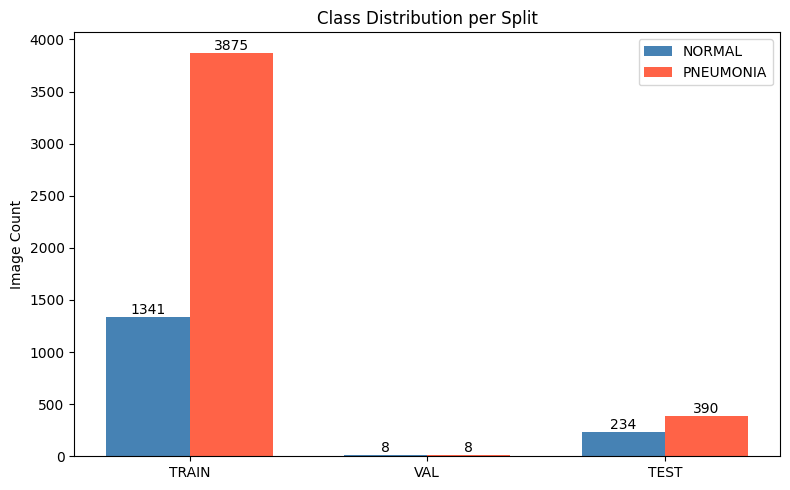

Train imbalance  NORMAL:PNEUMONIA = 1:2.9


In [ ]:
# Class distribution bar chart
splits = ['train', 'val', 'test']
counts = {
    s: {c: len(os.listdir(os.path.join(DATASET_ROOT, s, c))) for c in CLASSES}
    for s in splits
}

x, width = np.arange(len(splits)), 0.35
fig, ax = plt.subplots(figsize=(8, 5))
b1 = ax.bar(x - width/2, [counts[s]['NORMAL']    for s in splits], width, label='NORMAL',    color='steelblue')
b2 = ax.bar(x + width/2, [counts[s]['PNEUMONIA'] for s in splits], width, label='PNEUMONIA', color='tomato')
ax.set_xticks(x); ax.set_xticklabels([s.upper() for s in splits])
ax.set_ylabel('Image Count'); ax.set_title('Class Distribution per Split')
ax.legend(); ax.bar_label(b1); ax.bar_label(b2)
plt.tight_layout(); plt.show()

n, p = counts['train']['NORMAL'], counts['train']['PNEUMONIA']
print(f'Train imbalance  NORMAL:PNEUMONIA = 1:{p/n:.1f}')

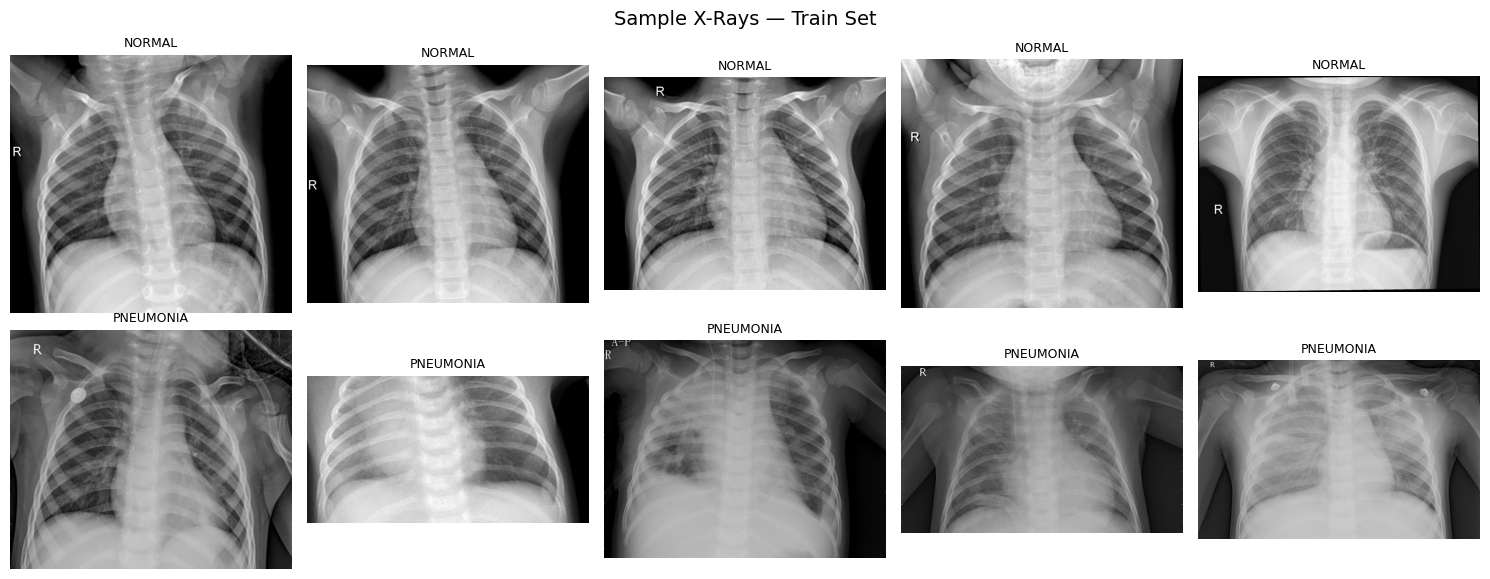

In [ ]:
# Sample X-rays from each class
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
fig.suptitle('Sample X-Rays — Train Set', fontsize=14)
for row, cls in enumerate(CLASSES):
    imgs = glob(os.path.join(DATASET_ROOT, 'train', cls, '*.jpeg'))
    for col, path in enumerate(random.sample(imgs, 5)):
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        axes[row, col].imshow(img, cmap='gray')
        axes[row, col].set_title(cls, fontsize=9)
        axes[row, col].axis('off')
plt.tight_layout(); plt.show()

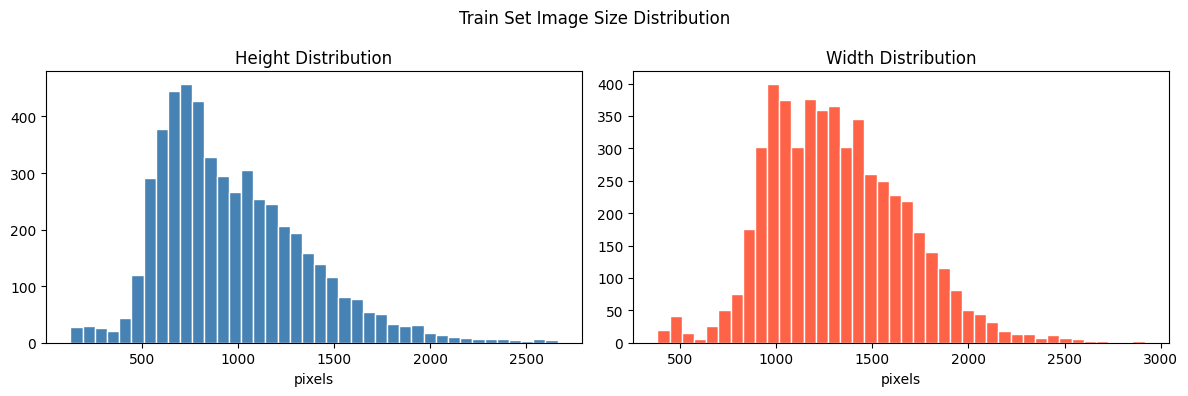

Height — min:127  max:2663  mean:968
Width  — min:384   max:2916   mean:1321


In [ ]:
# Image size distribution
heights, widths = [], []
for cls in CLASSES:
    for p in glob(os.path.join(DATASET_ROOT, 'train', cls, '*.jpeg')):
        img = cv2.imread(p)
        if img is not None:
            h, w = img.shape[:2]
            heights.append(h); widths.append(w)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(heights, bins=40, color='steelblue', edgecolor='white')
axes[0].set_title('Height Distribution'); axes[0].set_xlabel('pixels')
axes[1].hist(widths,  bins=40, color='tomato',    edgecolor='white')
axes[1].set_title('Width Distribution');  axes[1].set_xlabel('pixels')
plt.suptitle('Train Set Image Size Distribution')
plt.tight_layout(); plt.show()

print(f'Height — min:{min(heights)}  max:{max(heights)}  mean:{np.mean(heights):.0f}')
print(f'Width  — min:{min(widths)}   max:{max(widths)}   mean:{np.mean(widths):.0f}')

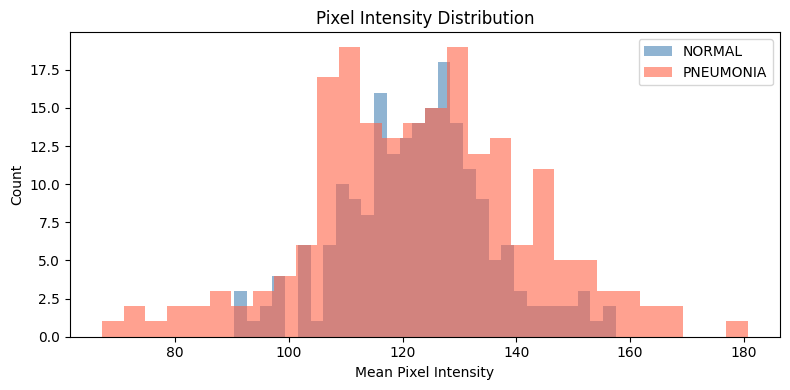

NORMAL    mean intensity: 122.78
PNEUMONIA mean intensity: 122.91


In [ ]:
# Pixel intensity distribution (NORMAL vs PNEUMONIA)
normal_means, pneumo_means = [], []
for p in random.sample(glob(os.path.join(DATASET_ROOT, 'train', 'NORMAL',    '*.jpeg')), 200):
    img = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    if img is not None: normal_means.append(img.mean())
for p in random.sample(glob(os.path.join(DATASET_ROOT, 'train', 'PNEUMONIA', '*.jpeg')), 200):
    img = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    if img is not None: pneumo_means.append(img.mean())

plt.figure(figsize=(8, 4))
plt.hist(normal_means, bins=30, alpha=0.6, label='NORMAL',    color='steelblue')
plt.hist(pneumo_means, bins=30, alpha=0.6, label='PNEUMONIA', color='tomato')
plt.xlabel('Mean Pixel Intensity'); plt.ylabel('Count')
plt.title('Pixel Intensity Distribution'); plt.legend()
plt.tight_layout(); plt.show()

print(f'NORMAL    mean intensity: {np.mean(normal_means):.2f}')
print(f'PNEUMONIA mean intensity: {np.mean(pneumo_means):.2f}')

## 4. Merge Val → Train (val has only 16 images — too small)

In [ ]:
for cls in CLASSES:
    src = os.path.join(DATASET_ROOT, 'val',   cls)
    dst = os.path.join(DATASET_ROOT, 'train', cls)
    for f in os.listdir(src):
        shutil.copy(os.path.join(src, f), os.path.join(dst, f))

print('Val merged into train.')
for cls in CLASSES:
    print(f'  {cls}: {len(os.listdir(os.path.join(DATASET_ROOT, "train", cls)))} images')

Val merged into train.
  NORMAL: 1349 images
  PNEUMONIA: 3883 images


## 5. Data Pipeline
**Normalization**: `preprocess_input` from ResNet50 subtracts ImageNet channel means (BGR) — correct range for pretrained weights, better than simple `/255`.

**Augmentation**: Applied only during training. NORMAL gets stronger augmentation (more flips/rotations/zoom) to compensate for its smaller count (1:2.9 imbalance).

**Class imbalance**: Handled two ways — (1) balanced batch generator draws equal batches from each class, (2) sample weights baked into generator output so the loss is weighted without needing `class_weight` argument (which Keras 3 does not support for Python generators).

In [ ]:
# ── UPDATED v2: Stronger augmentation + brightness jitter ──
# OLD augmentation (commented out):
# normal_datagen = ImageDataGenerator(
#     preprocessing_function=preprocess_input,
#     horizontal_flip=True, rotation_range=15, zoom_range=0.15,
#     width_shift_range=0.1, height_shift_range=0.1, shear_range=0.1)

# NEW v2 — stronger for NORMAL (minority class)
normal_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    horizontal_flip=True,
    rotation_range=20,
    zoom_range=0.20,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.10,
    brightness_range=[0.8, 1.2],
    fill_mode='nearest',
)
pneumonia_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    horizontal_flip=True,
    rotation_range=10,
    zoom_range=0.10,
    width_shift_range=0.10,
    height_shift_range=0.10,
    brightness_range=[0.85, 1.15],
    fill_mode='nearest',
)
eval_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

# Per-class flows
normal_train_gen = normal_datagen.flow_from_directory(
    os.path.join(DATASET_ROOT, 'train'), classes=['NORMAL'],
    target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE//2,
    class_mode='binary', seed=SEED)
pneumonia_train_gen = pneumonia_datagen.flow_from_directory(
    os.path.join(DATASET_ROOT, 'train'), classes=['PNEUMONIA'],
    target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE//2,
    class_mode='binary', seed=SEED)
test_gen = eval_datagen.flow_from_directory(
    os.path.join(DATASET_ROOT, 'test'),
    target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
    class_mode='binary', shuffle=False)

def balanced_generator(gen_a, gen_b):
    w_normal, w_pneu = 2.0, 1.0
    while True:
        x0, y0 = next(gen_a)
        x1, y1 = next(gen_b)
        x = np.concatenate([x0, x1])
        y = np.concatenate([y0, y1])
        w = np.where(y == 0, w_normal, w_pneu)
        yield x, y, w

train_gen = balanced_generator(normal_train_gen, pneumonia_train_gen)
steps_per_epoch = (len(normal_train_gen) + len(pneumonia_train_gen)) // 2
print(f'Steps per epoch: {steps_per_epoch}')


Found 1080 images belonging to 1 classes.
Found 3107 images belonging to 1 classes.
Sample weight  NORMAL:1.938  PNEUMONIA:0.674
Found 1045 images belonging to 2 classes.
Found 624 images belonging to 2 classes.
Class indices: {'NORMAL': 0, 'PNEUMONIA': 1}
Steps per epoch: 134


## 6. Model — DenseNet121 + Custom Classifier Head


In [ ]:
# ── UPDATED v2: DenseNet121 backbone instead of ResNet50 ──
# OLD (commented out):
# def build_model(trainable_base=False):
#     base = ResNet50(include_top=False, weights='imagenet', input_shape=(224,224,3))
#     base.trainable = trainable_base
#     inputs = keras.Input(shape=(224,224,3))
#     x = base(inputs, training=False)
#     x = layers.GlobalAveragePooling2D()(x)
#     x = layers.BatchNormalization()(x)
#     x = layers.Dense(256, activation='relu')(x)
#     x = layers.Dropout(0.4)(x)
#     x = layers.Dense(64, activation='relu')(x)
#     x = layers.Dropout(0.2)(x)
#     outputs = layers.Dense(1, activation='sigmoid')(x)
#     return keras.Model(inputs, outputs)

# NEW v2 — DenseNet121 with wider head
def build_model(trainable_base=False):
    base = DenseNet121(
        include_top=False,
        weights='imagenet',
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    base.trainable = trainable_base

    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='input_image')
    x = base(inputs, training=False)

    x = layers.GlobalAveragePooling2D(name='gap')(x)
    x = layers.BatchNormalization(name='bn')(x)
    x = layers.Dense(512, activation='relu', name='dense_512')(x)  # was 256
    x = layers.Dropout(0.5, name='dropout_05')(x)                   # was 0.4
    x = layers.Dense(128, activation='relu', name='dense_128')(x)   # was 64
    x = layers.Dropout(0.3, name='dropout_03')(x)                   # was 0.2
    outputs = layers.Dense(1, activation='sigmoid', name='output')(x)

    return keras.Model(inputs, outputs, name='pneumonia_densenet121')

model      = build_model(trainable_base=False)
base_model = model.get_layer('densenet121')
model.summary()


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,136,961 (92.08 MB)

 Trainable params: 545,153 (2.08 MB)

 Non-trainable params: 23,591,808 (90.00 MB)

## 7. Phase 1 — Train Classifier Head (base frozen)

In [ ]:
# ── UPDATED v2: Focal Loss instead of binary_crossentropy ──
# OLD (commented out):
# model.compile(
#     optimizer=keras.optimizers.Adam(1e-3),
#     loss='binary_crossentropy',
#     metrics=['accuracy', keras.metrics.AUC(name='auc'), keras.metrics.Recall(name='recall')])

# NEW v2 — Focal Loss
def focal_loss(gamma=2.0, alpha=0.25):
    """Focuses training on hard, misclassified examples."""
    def loss_fn(y_true, y_pred):
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1 - 1e-7)
        pt = tf.where(tf.equal(y_true, 1), y_pred, 1 - y_pred)
        return tf.reduce_mean(-alpha * tf.pow(1 - pt, gamma) * tf.math.log(pt))
    return loss_fn

model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss=focal_loss(gamma=2.0, alpha=0.25),
    metrics=[
        'accuracy',
        keras.metrics.AUC(name='auc'),
        keras.metrics.Recall(name='recall'),
        keras.metrics.Precision(name='precision'),  # NEW
    ]
)

callbacks_p1 = [
    keras.callbacks.EarlyStopping(
        monitor='val_auc', patience=5,
        restore_best_weights=True, mode='max', verbose=1),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_auc', factor=0.5, patience=3,
        min_lr=1e-7, mode='max', verbose=1),
    keras.callbacks.ModelCheckpoint(
        'best_phase1.h5', monitor='val_auc',
        save_best_only=True, mode='max', verbose=1),
]

history1 = model.fit(
    train_gen,
    steps_per_epoch=steps_per_epoch,
    epochs=EPOCHS_HEAD,
    validation_data=test_gen,
    callbacks=callbacks_p1,
    verbose=1,
)


Epoch 1/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 162s 1s/step - accuracy: 0.9467 - auc: 0.9877 - loss: 0.1468 - recall: 0.9207 - val_accuracy: 0.8852 - val_auc: 0.9953 - val_loss: 0.2742 - val_recall: 0.8454 - learning_rate: 0.0010
Epoch 2/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 124s 934ms/step - accuracy: 0.9608 - auc: 0.9915 - loss: 0.1107 - recall: 0.9381 - val_accuracy: 0.9273 - val_auc: 0.9950 - val_loss: 0.1863 - val_recall: 0.9021 - learning_rate: 0.0010
Epoch 3/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 118s 887ms/step - accuracy: 0.9690 - auc: 0.9929 - loss: 0.0989 - recall: 0.9503 - val_accuracy: 0.8813 - val_auc: 0.9908 - val_loss: 0.3521 - val_recall: 0.8402 - learning_rate: 0.0010
Epoch 4/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 118s 884ms/step - accuracy: 0.9738 - auc: 0.9941 - loss: 0.0819 - recall: 0.9562 - val_accuracy: 0.9378 - val_auc: 0.9964 - val_loss: 0.1892 - val_recall: 0.9162 - learning_rate: 0.0010
Epoch 5/10
134/134 ━━━━━━━━━━━━━━━━━━━━ 0s 761ms/step - accuracy: 0.9735 - auc: 0.9958 - loss: 0.07

## 8. Phase 2 — Fine-tune Top Layers of DenseNet121


In [ ]:
# ── UPDATED v2: Cosine LR Decay + unfreeze top 50 layers (DenseNet121) ──
# OLD (commented out):
# base_model.trainable = True
# for layer in base_model.layers[:-30]: layer.trainable = False
# model.compile(optimizer=keras.optimizers.Adam(1e-4), loss='binary_crossentropy', ...)

base_model.trainable = True
# DenseNet121 has 427 layers — unfreeze top 50
for layer in base_model.layers[:-50]:   # was [:-30] for ResNet50
    layer.trainable = False

trainable = sum(1 for l in base_model.layers if l.trainable)
print(f'Trainable base layers: {trainable} / {len(base_model.layers)}')

# Cosine Decay LR — smoothly reduces from 1e-4 to near zero
total_steps = steps_per_epoch * EPOCHS_FINE
lr_schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=1e-4,
    decay_steps=total_steps,
    alpha=1e-6,
)

model.compile(
    optimizer=keras.optimizers.Adam(lr_schedule),
    loss=focal_loss(gamma=2.0, alpha=0.25),
    metrics=[
        'accuracy',
        keras.metrics.AUC(name='auc'),
        keras.metrics.Recall(name='recall'),
        keras.metrics.Precision(name='precision'),
    ]
)

callbacks_p2 = [
    keras.callbacks.EarlyStopping(
        monitor='val_auc', patience=7,
        restore_best_weights=True, mode='max', verbose=1),
    keras.callbacks.ModelCheckpoint(
        'best_phase2.h5', monitor='val_auc',
        save_best_only=True, mode='max', verbose=1),
]

history2 = model.fit(
    train_gen,
    steps_per_epoch=steps_per_epoch,
    epochs=EPOCHS_FINE,
    validation_data=test_gen,
    callbacks=callbacks_p2,
    verbose=1,
)


Trainable layers in base: 30 / 175
Epoch 1/15
134/134 ━━━━━━━━━━━━━━━━━━━━ 242s 2s/step - accuracy: 0.9735 - auc: 0.9947 - loss: 0.0806 - recall: 0.9611 - val_accuracy: 0.9789 - val_auc: 0.9913 - val_loss: 0.0753 - val_recall: 0.9884 - learning_rate: 1.0000e-04
Epoch 2/15
134/134 ━━━━━━━━━━━━━━━━━━━━ 168s 1s/step - accuracy: 0.9800 - auc: 0.9977 - loss: 0.0567 - recall: 0.9695 - val_accuracy: 0.9761 - val_auc: 0.9957 - val_loss: 0.0726 - val_recall: 0.9716 - learning_rate: 1.0000e-04
Epoch 3/15
134/134 ━━━━━━━━━━━━━━━━━━━━ 167s 1s/step - accuracy: 0.9888 - auc: 0.9994 - loss: 0.0277 - recall: 0.9823 - val_accuracy: 0.9177 - val_auc: 0.9891 - val_loss: 0.2925 - val_recall: 0.8892 - learning_rate: 1.0000e-04
Epoch 4/15
134/134 ━━━━━━━━━━━━━━━━━━━━ 168s 1s/step - accuracy: 0.9854 - auc: 0.9987 - loss: 0.0375 - recall: 0.9784 - val_accuracy: 0.9187 - val_auc: 0.9943 - val_loss: 0.2159 - val_recall: 0.8905 - learning_rate: 1.0000e-04
Epoch 5/15
134/134 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accu

## 9. Training Curves

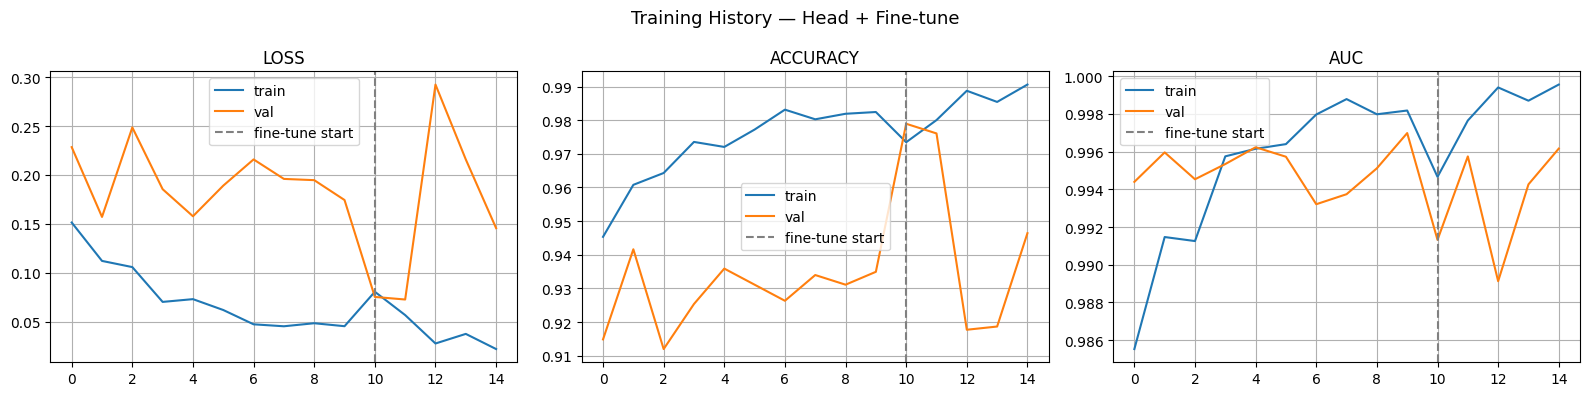

In [ ]:
def plot_history(h1, h2, metric, ax):
    values     = h1.history[metric]         + h2.history[metric]
    val_values = h1.history[f'val_{metric}'] + h2.history[f'val_{metric}']
    ax.plot(values,     label='train')
    ax.plot(val_values, label='val')
    ax.axvline(len(h1.history[metric]), color='gray', linestyle='--', label='fine-tune start')
    ax.set_title(metric.upper()); ax.legend(); ax.grid(True)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, m in zip(axes, ['loss', 'accuracy', 'auc']):
    plot_history(history1, history2, m, ax)
plt.suptitle('Training History — Head + Fine-tune', fontsize=13)
plt.tight_layout(); plt.show()

## 10. Evaluation on Test Set

In [ ]:
# ── UPDATED v2: TTA (Test-Time Augmentation) for better accuracy ──
# OLD (commented out):
# test_gen.reset()
# y_true = test_gen.classes
# y_pred_prob = model.predict(test_gen, verbose=1).flatten()
# y_pred = (y_pred_prob > 0.5).astype(int)

# NEW v2 — Average predictions over N augmented versions of each test image
tta_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    horizontal_flip=True,
    rotation_range=5,
    zoom_range=0.05,
)

tta_preds = []
for i in range(N_TTA):
    tta_gen = tta_datagen.flow_from_directory(
        os.path.join(DATASET_ROOT, 'test'),
        target_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE,
        class_mode='binary',
        shuffle=False,
        seed=i * 7,
    )
    tta_preds.append(model.predict(tta_gen, verbose=0).flatten())
    print(f'TTA pass {i+1}/{N_TTA} done')

y_pred_prob = np.mean(tta_preds, axis=0)  # ensemble average

test_gen.reset()
y_true = test_gen.classes
y_pred = (y_pred_prob > THRESHOLD).astype(int)

print(f'\nTTA passes: {N_TTA}  |  Threshold: {THRESHOLD}')
print('\n── Classification Report ──')
print(classification_report(y_true, y_pred, target_names=['NORMAL', 'PNEUMONIA']))
print(f'AUC-ROC: {roc_auc_score(y_true, y_pred_prob):.4f}')


20/20 ━━━━━━━━━━━━━━━━━━━━ 21s 762ms/step

── Classification Report ──
              precision    recall  f1-score   support

      NORMAL       0.98      0.41      0.58       234
   PNEUMONIA       0.74      0.99      0.85       390

    accuracy                           0.78       624
   macro avg       0.86      0.70      0.71       624
weighted avg       0.83      0.78      0.75       624

AUC-ROC: 0.9576


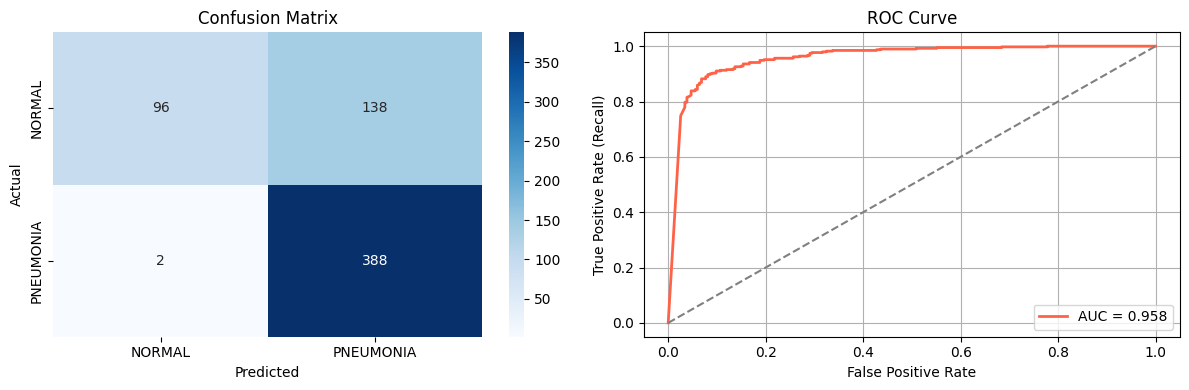

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['NORMAL', 'PNEUMONIA'],
            yticklabels=['NORMAL', 'PNEUMONIA'], ax=axes[0])
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

# ROC curve
fpr, tpr, _ = roc_curve(y_true, y_pred_prob)
auc_score   = roc_auc_score(y_true, y_pred_prob)
axes[1].plot(fpr, tpr, label=f'AUC = {auc_score:.3f}', color='tomato', lw=2)
axes[1].plot([0, 1], [0, 1], '--', color='gray')
axes[1].set_title('ROC Curve')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate (Recall)')
axes[1].legend(); axes[1].grid(True)

plt.tight_layout(); plt.show()

In [ ]:
from sklearn.metrics import f1_score

thresholds = np.arange(0.1, 0.9, 0.01)
f1_scores  = [f1_score(y_true, (y_pred_prob > t).astype(int)) for t in thresholds]
best_thresh = thresholds[np.argmax(f1_scores)]

plt.figure(figsize=(8, 4))
plt.plot(thresholds, f1_scores, color='steelblue')
plt.axvline(best_thresh, color='tomato', linestyle='--', label=f'Best = {best_thresh:.2f}')
plt.xlabel('Threshold'); plt.ylabel('F1 Score')
plt.title('F1 Score vs Threshold'); plt.legend(); plt.grid(True)
plt.tight_layout(); plt.show()

print(f'Best threshold: {best_thresh:.2f}')

In [ ]:
y_pred_tuned = (y_pred_prob > best_thresh).astype(int)

print(f'── Results at threshold = {best_thresh:.2f} ──')
print(classification_report(y_true, y_pred_tuned, target_names=['NORMAL', 'PNEUMONIA']))
print(f'AUC-ROC: {roc_auc_score(y_true, y_pred_prob):.4f}')

cm2 = confusion_matrix(y_true, y_pred_tuned)
tn, fp, fn, tp = cm2.ravel()
print(f'\nTP={tp}  TN={tn}  FP={fp}  FN={fn}')
print(f'Sensitivity (Recall PNEUMONIA) : {tp/(tp+fn):.4f}')
print(f'Specificity (Recall NORMAL)    : {tn/(tn+fp):.4f}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(cm2, annot=True, fmt='d', cmap='Blues',
            xticklabels=['NORMAL','PNEUMONIA'],
            yticklabels=['NORMAL','PNEUMONIA'], ax=axes[0])
axes[0].set_title(f'Confusion Matrix (threshold={best_thresh:.2f})')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

fpr, tpr, _ = roc_curve(y_true, y_pred_prob)
axes[1].plot(fpr, tpr, lw=2, color='tomato', label=f'AUC = {roc_auc_score(y_true, y_pred_prob):.3f}')
axes[1].plot([0,1],[0,1],'--',color='gray')
axes[1].set_title('ROC Curve'); axes[1].grid(True)
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(); plt.tight_layout(); plt.show()

In [ ]:
all_paths = [os.path.join(test_gen.directory, f) for f in test_gen.filenames]

fp_list, fn_list = [], []
for path, true, pred, prob in zip(all_paths, y_true, y_pred_tuned, y_pred_prob):
    if true == 0 and pred == 1: fp_list.append((path, prob))  # Normal → Pneumonia bola
    if true == 1 and pred == 0: fn_list.append((path, prob))  # Pneumonia → Normal bola

print(f'False Positives (Normal ko Pneumonia bola) : {len(fp_list)}')
print(f'False Negatives (Pneumonia ko Normal bola) : {len(fn_list)}  ← Dangerous!')

for lst, title in [(fp_list[:5], 'False Positives — Normal ko Pneumonia bola'),
                   (fn_list[:5], 'False Negatives — Pneumonia miss kiya (DANGEROUS)')]:
    if not lst: continue
    fig, axes = plt.subplots(1, len(lst), figsize=(15, 3))
    fig.suptitle(title, fontsize=11)
    if len(lst) == 1: axes = [axes]
    for ax, (path, prob) in zip(axes, lst):
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        ax.imshow(img, cmap='gray')
        ax.set_title(f'P={prob:.2f}', fontsize=9)
        ax.axis('off')
    plt.tight_layout(); plt.show()

## 11. Experiment Tracking — MLflow


In [ ]:
# ── NEW v2: Log experiment with MLflow ──
if MLFLOW_AVAILABLE:
    from sklearn.metrics import f1_score, accuracy_score
    cm = confusion_matrix(y_true, y_pred)

    mlflow.set_experiment('pneumonia-xray-classification')
    with mlflow.start_run(run_name='densenet121-focal-cosine-tta'):
        mlflow.log_params({
            'backbone':        'DenseNet121',
            'img_size':        IMG_SIZE,
            'batch_size':      BATCH_SIZE,
            'epochs_head':     EPOCHS_HEAD,
            'epochs_fine':     EPOCHS_FINE,
            'loss':            'focal_loss(gamma=2, alpha=0.25)',
            'lr_phase1':       '1e-3 Adam',
            'lr_phase2':       'CosineDecay(1e-4 → 1e-6)',
            'tta_passes':      N_TTA,
            'threshold':       THRESHOLD,
            'unfreeze_layers': 50,
        })
        mlflow.log_metrics({
            'test_accuracy':    round(accuracy_score(y_true, y_pred), 4),
            'test_auc_roc':     round(roc_auc_score(y_true, y_pred_prob), 4),
            'normal_recall':    round(cm[0,0] / cm[0].sum(), 4),
            'pneumonia_recall': round(cm[1,1] / cm[1].sum(), 4),
            'f1_weighted':      round(f1_score(y_true, y_pred, average='weighted'), 4),
        })
        mlflow.keras.log_model(model, artifact_path='densenet121_model')
        print('MLflow run logged!')
        print('View UI: run  mlflow ui  in terminal')
else:
    print('MLflow not available. pip install mlflow')


## 12. Save Model


In [ ]:
save_path = '/content/drive/MyDrive/Colab Notebooks/pneumonia_resnet50.h5'
model.save(save_path)
print(f'Model saved → {save_path}')

Model saved → /content/drive/MyDrive/Colab Notebooks/pneumonia_resnet50.h5
